In [3]:
import joblib
temp_random_CV = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\5_2_Model_Training_With_Tuning\Saved_Model\XGB_Tuned")

best_model = temp_random_CV.best_estimator_

In [6]:
import pandas as pd
import numpy as np

x_train = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_train")
x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_test")

print(f"x_train shape : {x_train.shape}")
print(f"x_test shape : {x_test.shape}")

x_train shape : (5634, 33)
x_test shape : (1409, 33)


In [7]:
x_full = pd.concat([x_train, x_test], ignore_index = True)

In [31]:
x_full.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'InternetService_Fiber optic',
       'InternetService_No', 'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'TotalCharges_log', 'TotalServices', 'TechServices_Support',
       'AvgMonthlyCharges', 'ChargeInflationRatio', 'CostperService',
       'IsNewCust', 'IsLongTermCust', 'IsMonth_to_Month',
       'RiskyCustomerProfile', 'HasFamily'],
      dtype='str')

In [10]:
churn_probs = best_model.predict_proba(x_full)[:, 1]


risk_df = pd.DataFrame({
    'churn_prob' : churn_probs
}, index = x_full.index)

In [11]:
risk_df["risk_segment"] = pd.cut(
    risk_df["churn_prob"],
    bins = [-np.inf, 0.30, 0.70, np.inf],
    labels = ["Low", "Medium", "High"],
    right = False
)

actions = {
    "Low" : "Normal Engagement",
    "Medium" : "Monitor and targeted engagement",
    "High" : "Proactive retention action"
}

risk_df["Recommended_Action"] = (risk_df["risk_segment"]).astype(str).map(actions)

In [15]:
risk_df = risk_df.sort_values(by = "churn_prob", ascending = False)
print(risk_df.head(10))

      churn_prob risk_segment          Recommended_Action
4130    0.930894         High  Proactive retention action
1615    0.930894         High  Proactive retention action
6724    0.930439         High  Proactive retention action
985     0.923037         High  Proactive retention action
3877    0.921265         High  Proactive retention action
3631    0.917458         High  Proactive retention action
4244    0.916737         High  Proactive retention action
920     0.916030         High  Proactive retention action
1027    0.915964         High  Proactive retention action
742     0.915964         High  Proactive retention action


In [16]:
risk_summary = (
    risk_df.groupby("risk_segment", observed = False).agg(
        customer_count = ("churn_prob", "size"),
        avg_churn_probability = ("churn_prob", "mean")
    )
)

risk_summary["customer_%"] = (
    risk_summary["customer_count"] / risk_summary["customer_count"].sum() * 100
)

print(risk_summary["customer_%"].round(2))

risk_segment
Low       54.08
Medium    33.47
High      12.45
Name: customer_%, dtype: float64


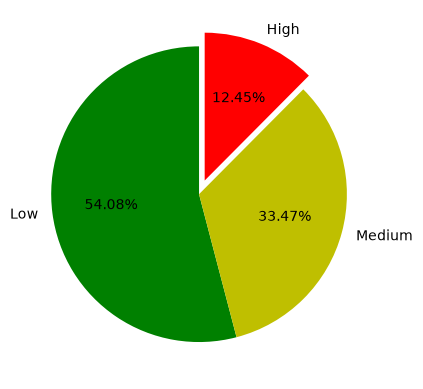

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.pie(risk_summary["customer_%"], labels = risk_summary.index, startangle = 90, autopct = '%1.2f%%', explode = [0, 0, 0.1], colors = ["g", "y", "r"])

### Checking certain trends or patterns for different segments of customers based on numeric features

In [32]:
segment_df = x_full.join(risk_df[["churn_prob", "risk_segment"]], how = 'inner')

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges_log"]

profile = segment_df.groupby(
    "risk_segment", observed = False
)[numeric_cols].agg(["mean", "median"])

print(profile.round(2))


             tenure        MonthlyCharges        TotalCharges_log       
               mean median           mean median             mean median
risk_segment                                                            
Low            0.47   0.63          -0.29  -0.30             0.28   0.38
Medium        -0.37  -0.59           0.25   0.46            -0.14   0.20
High          -1.10  -1.20           0.53   0.55            -0.88  -0.83


Upon summarizing the numeric columns for different churn risk based segments, we could observe that :
- High churn risk customers tend to have shorter tenure period, greater monthly charges and lower total charges compared to other segments.
- Low churn risk customers tend to have longer tenure period, lower monthly charges, and somewhat greater total charges (aggregated).

The difference in trends for total charges is due to certain customers sticking to longer tenure periods and subscribing to more plans and services which raises their total charges, even if the monthly charges are lower. Conversely, for high churn risk customers, due to the high monthly charges combined with their shorter tenure period leads to lower total charges for this segment.

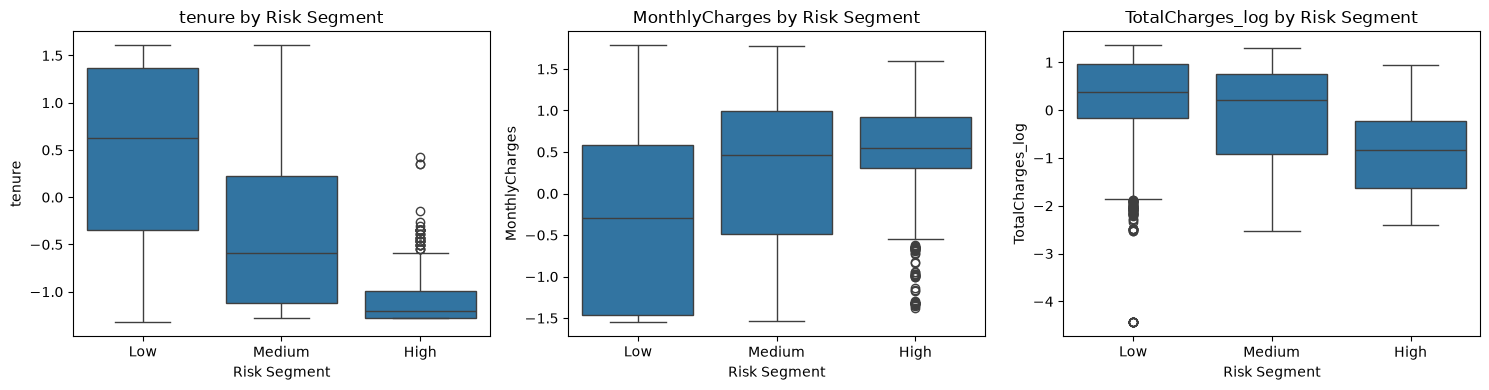

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

features = ["tenure", "MonthlyCharges", "TotalCharges_log"]

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=segment_df,
        x="risk_segment",
        y=feature,
        order=["Low", "Medium", "High"],
        ax=ax
    )
    ax.set_title(f"{feature} by Risk Segment")
    ax.set_xlabel("Risk Segment")

plt.tight_layout()
plt.show()

### Checking patterns and trends for different customer segments based on categorical features

In [33]:
contract_profile = pd.crosstab(segment_df["risk_segment"], segment_df["IsMonth_to_Month"], normalize = "index") * 100
print(contract_profile.round(1))

IsMonth_to_Month     0      1
risk_segment                 
Low               78.1   21.9
Medium             8.1   91.9
High               0.0  100.0


In [36]:
contract_profile = pd.crosstab(segment_df["risk_segment"], segment_df['PaymentMethod_Electronic check'], normalize = "index") * 100
print(contract_profile.round(1))

PaymentMethod_Electronic check     0     1
risk_segment                              
Low                             85.6  14.4
Medium                          52.6  47.4
High                            20.2  79.8


In [38]:
contract_profile = pd.crosstab(segment_df["risk_segment"], segment_df['InternetService_No'], normalize = "index") * 100
print(contract_profile.round(1))

InternetService_No      0     1
risk_segment                   
Low                  64.3  35.7
Medium               93.0   7.0
High                100.0   0.0


In [39]:
contract_profile = pd.crosstab(segment_df["risk_segment"], segment_df['TechSupport'], normalize = "index") * 100
print(contract_profile.round(1))

TechSupport      0     1
risk_segment            
Low           60.4  39.6
Medium        80.0  20.0
High          92.6   7.4


In [40]:
contract_profile = pd.crosstab(segment_df["risk_segment"], segment_df['OnlineSecurity'], normalize = "index") * 100
print(contract_profile.round(1))

OnlineSecurity     0     1
risk_segment              
Low             60.5  39.5
Medium          80.1  19.9
High            95.0   5.0


Business Action Recommendations based on observed patterns and trends in the data for different risk segments: 
- Those with shorter tenure periods (typically less than an year) have high chances of Churning. Promotional offers on taking an yearly plan can be issued to high risk segment customers to retain them.
- Customers with monthly to monthly payments instead of yearly based contracts tend to Churn at a higher rate. Potentially, some kind of bundle offer or discount on taking an yearly subscription could lead them to change their plans and retain the service usage.
- Customers with higher Total Charges (all the plans combined with any form of support/service) tend to stay for longer, and churn less, and those with lower Total Charges are Churning greater. This could suggest that due to the additional plans and support that customers take are useful for customers leading them pay the subscription regularly. And, the customers with longer tenure period or yearly based contract, they will end up having greater Total Costs but followed with the additional services and packs combined, they might end up sticking to it, instead of Churning.
- It appeared that the majority of customers who churned (with high risk) had electronic check as payment method. But in other risk segments (low, medium), these customers had lower percentages of using electronic check as payment method. This is a sign that there is a problem with this payment mode for most customers, or there is potentially some drawbacks for customers using this payment method. Either eliminating this payment method, or trying to improve this could make changes in churn risk.
- There is a significant fraction of customers across medium and high churn risk, who didn't opt for Tech Support or Online Security. While it is not direct correlation, promoting additional offers for Tech Support and Online Security might end up convincing the customer to opt more frequently and consistently.